# 05 · Incrementality and Marketing Mix Model (MMM)

**Business question:** how many orders does each media channel *really* drive, that is, orders that would not happen without the ad? Platform ROAS and last click answer a different question ("who got the credit") and overestimate bottom-of-funnel channels such as remarketing and brand search.

**Design, in two parts:**
1. **Pause test:** all Meta prospecting was turned off from Aug 4 to Aug 24, 2025. We compare the orders during the pause with a counterfactual fitted on the neighboring weeks. It is the cleanest causal measure in the base, but it covers a single channel.
2. **MMM:** a regression of daily orders on the spend of 6 channels, with geometric *adstock* (an effect that carries over to the following days) and Hill saturation (diminishing returns), plus calendar controls. The pause test is the reference for the channel it measures.

Since the base is synthetic, at the end we compare the estimates with the **generator's truth** (`data/verdade/`), something impossible in a real store.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy.optimize import lsq_linear
from utils_nb import sql, configurar_graficos, verdade, brl, CORES, COR_REAL, COR_PREVISTO, COR_DESTAQUE

configurar_graficos()
CANAIS = ["meta_prospeccao", "meta_remarketing", "google_marca", "google_search", "google_shopping_pmax", "google_demand_gen"]
ROTULO = {"meta_prospeccao": "Meta prospecção", "meta_remarketing": "Meta remarketing", "google_marca": "Google marca",
          "google_search": "Google search (genérico)", "google_shopping_pmax": "Google Shopping/PMax", "google_demand_gen": "Google Demand Gen"}

## Data: orders and spend by channel, per day

In [2]:
ped = sql("""SELECT DATE(criado_em) AS data, COUNT(*) AS pedidos, SUM(total) AS receita
FROM pedidos WHERE pedido_teste = 0 AND status IN ('pago','enviado','entregue','devolvido')
GROUP BY DATE(criado_em)""")
inv = sql("""
SELECT m.data, IF(c.nome LIKE '[RMKT]%', 'meta_remarketing', 'meta_prospeccao') AS canal,
       SUM(m.investimento) AS investimento, SUM(m.valor_compras) AS valor_reportado
FROM meta_metricas_diarias m JOIN meta_anuncios a USING (anuncio_id) JOIN meta_conjuntos j USING (conjunto_id)
JOIN meta_campanhas c ON c.campanha_id = j.campanha_id GROUP BY 1, 2
UNION ALL
SELECT m.data, CASE WHEN c.campanha_marca = 1 THEN 'google_marca' WHEN c.tipo_canal = 'SEARCH' THEN 'google_search'
                    WHEN c.tipo_canal = 'DEMAND_GEN' THEN 'google_demand_gen' ELSE 'google_shopping_pmax' END,
       SUM(m.investimento), SUM(m.valor_conversao)
FROM google_metricas_diarias m JOIN google_grupos_anuncio g USING (grupo_id)
JOIN google_campanhas c ON c.campanha_id = g.campanha_id GROUP BY 1, 2""")
for d in (ped, inv):
    d["data"] = pd.to_datetime(d["data"])
X_inv = inv.pivot_table(index="data", columns="canal", values="investimento", aggfunc="sum").reindex(columns=CANAIS)
df = ped.set_index("data").join(X_inv, how="left").fillna(0.0).astype(float)
df = df.loc["2023-10-01":"2026-10-13"]
ticket = df.receita.sum() / df.pedidos.sum()
print(f"{len(df)} dias | {df.pedidos.sum():,.0f} pedidos | ticket médio {brl(ticket, 2)} | investimento {brl(df[CANAIS].sum().sum())}")
df[CANAIS].sum().rename(ROTULO).map(brl).to_frame("investimento no período")

1109 dias | 133,649 pedidos | ticket médio R$ 290,81 | investimento R$ 4.295.526


,investimento no período
Meta prospecção,R$ 1.969.950
Meta remarketing,R$ 533.554
Google marca,R$ 138.875
Google search (genérico),R$ 653.031
Google Shopping/PMax,R$ 937.242
Google Demand Gen,R$ 62.875


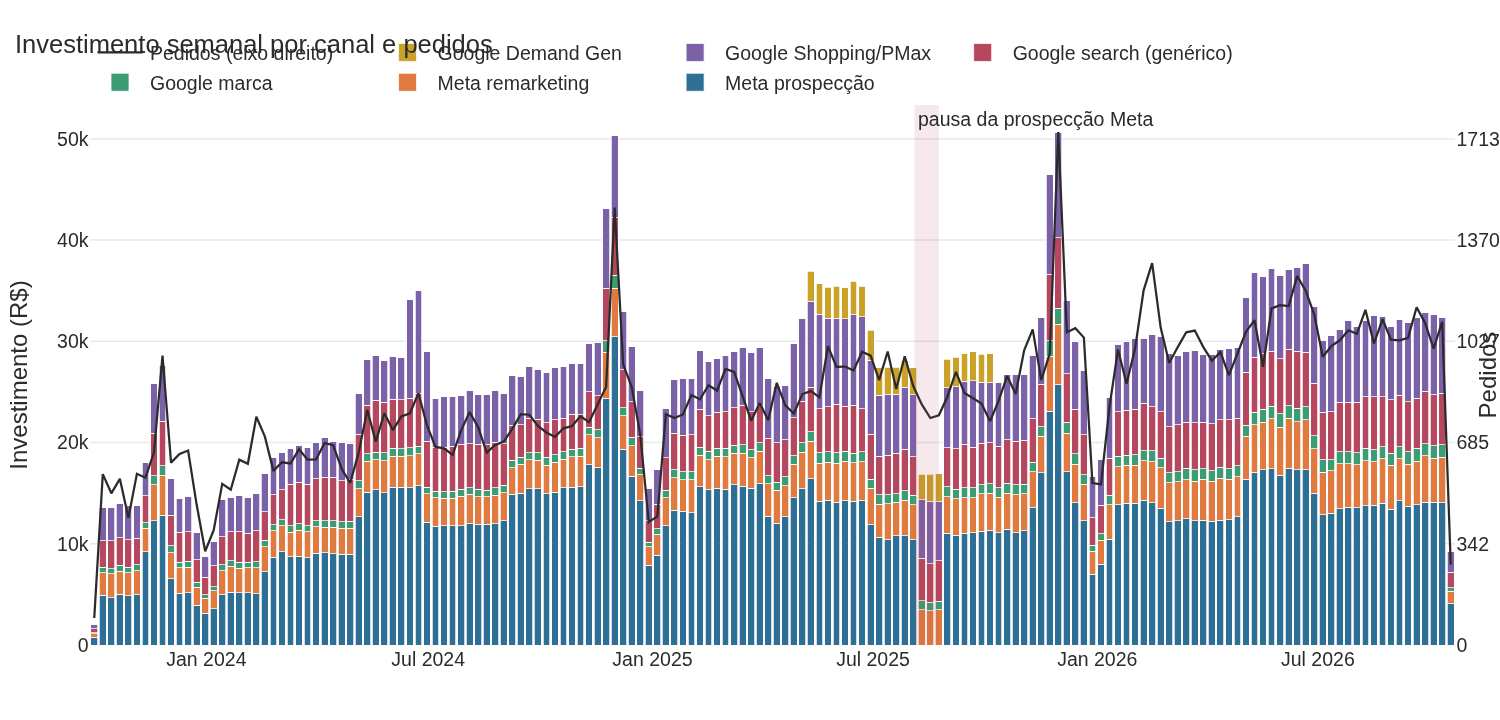

In [3]:
sem = df.resample("W").sum()
fig = go.Figure()
for i, c in enumerate(CANAIS):
    fig.add_bar(x=sem.index, y=sem[c], name=ROTULO[c], marker_color=CORES[i])
fig.add_scatter(x=sem.index, y=sem.pedidos, name="Pedidos (eixo direito)", yaxis="y2", line=dict(color="#2b2b2b", width=1.5))
fig.update_layout(barmode="stack", title="Investimento semanal por canal e pedidos", yaxis_title="Investimento (R$)",
                  yaxis2=dict(overlaying="y", side="right", showgrid=False, title="Pedidos"))
fig.add_vrect(x0="2025-08-04", x1="2025-08-24", fillcolor=COR_DESTAQUE, opacity=0.12, line_width=0,
              annotation_text="pausa da prospecção Meta", annotation_position="top left")
fig.show()

## 1. Meta prospecting pause test (Aug 4 to 24, 2025)

The counterfactual is a regression of orders on a linear trend and day of week, fitted on the 5 weeks before (excluding the June festivals) and the 3 weeks after the pause. The first week after the restart is left out, because the *adstock* is still rebuilding. The gap between predicted and actual during the pause is the lost effect.

Pedidos perdidos na pausa: 327 (±125, IC 95% aproximado)
Investimento que deixou de ser feito: R$ 32.272
Pedidos incrementais por R$ 1.000: 10.1  →  iROAS ≈ 2.95


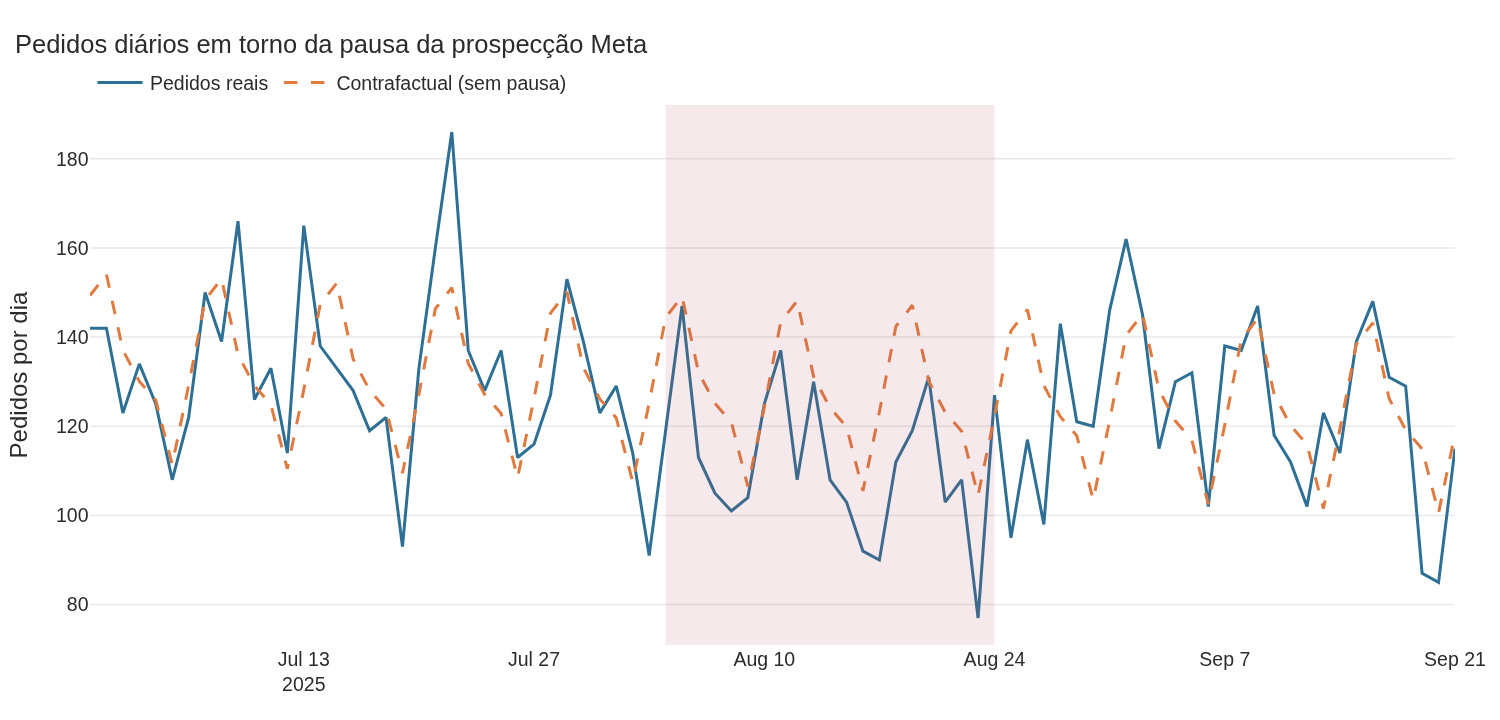

In [4]:
def calendario(idx):
    X = pd.DataFrame({"const": 1.0, "t": np.arange(len(idx)) / 100}, index=idx)
    for d in range(1, 7):
        X[f"dow{d}"] = (idx.dayofweek == d).astype(float)
    return X

janela = df.loc["2025-06-30":"2025-09-21", ["pedidos", "meta_prospeccao"]].copy()
pausa = (janela.index >= "2025-08-04") & (janela.index <= "2025-08-24")
retomada = (janela.index > "2025-08-24") & (janela.index <= "2025-08-31")
treino = ~pausa & ~retomada
Xc = calendario(janela.index)
coef, *_ = np.linalg.lstsq(Xc[treino].values, janela.pedidos[treino].values, rcond=None)
janela["contrafactual"] = Xc.values @ coef
resid_sd = (janela.pedidos - janela.contrafactual)[treino].std()

perdidos = (janela.contrafactual - janela.pedidos)[pausa].sum()
erro_padrao = resid_sd * np.sqrt(pausa.sum())
economia = janela.meta_prospeccao[treino].mean() * pausa.sum()
ped_por_mil_pausa = perdidos / economia * 1000
print(f"Pedidos perdidos na pausa: {perdidos:,.0f} (±{1.96 * erro_padrao:,.0f}, IC 95% aproximado)")
print(f"Investimento que deixou de ser feito: {brl(economia)}")
print(f"Pedidos incrementais por R$ 1.000: {ped_por_mil_pausa:.1f}  →  iROAS ≈ {ped_por_mil_pausa * ticket / 1000:.2f}")

fig = go.Figure()
fig.add_scatter(x=janela.index, y=janela.pedidos, name="Pedidos reais", line=dict(color=COR_REAL))
fig.add_scatter(x=janela.index, y=janela.contrafactual, name="Contrafactual (sem pausa)", line=dict(color=COR_PREVISTO, dash="dash"))
fig.add_vrect(x0="2025-08-04", x1="2025-08-24", fillcolor=COR_DESTAQUE, opacity=0.12, line_width=0)
fig.update_layout(title="Pedidos diários em torno da pausa da prospecção Meta", yaxis_title="Pedidos por dia")
fig.show()

## 2. Marketing Mix Model

For each channel, daily spend goes through:
- **geometric adstock** `A_t = x_t + λ·A_{t-1}`, with λ between 0 and 0.8;
- **Hill saturation** `A^a / (A^a + K^a)`, with `K` equal to a multiple of the adstock average on active days.

Daily orders are explained by these terms (coefficients ≥ 0) plus the controls: piecewise trend, yearly seasonality (Fourier), day of week, start of month (payday) and known retail dates. The hyperparameters (λ, `a` and `K` for each channel) are chosen by random search, evaluating the error on the **last 120 days, outside the fitting sample**. Then the model is refitted on the whole series.

We fit two versions:
- **uncalibrated**: time series data only;
- **calibrated**: the pause test result enters as the *prior* for Meta prospecting's iROAS (the test's mean and error), and the other channels get a weak prior (iROAS 1 ± 1). This is what tools such as Robyn and Meridian do with incrementality experiments.

Limitation: an MMM can only separate channels whose spend varies independently. Channels that always rise and fall together (for example, all growing on Black Friday) get unstable estimates. That is why the pause test is the anchor.

In [5]:
def adstock(x, lam):
    out, acc = np.empty_like(x), 0.0
    for i, v in enumerate(x):
        acc = v + lam * acc
        out[i] = acc
    return out

def hill(A, krel, a):
    ativo = A > 1e-6
    k = krel * (A[ativo].mean() if ativo.any() else 1.0)
    return A ** a / (A ** a + k ** a)

idx = df.index
datas = {
    "black_friday": [("2023-11-20", "2023-11-27"), ("2024-11-25", "2024-12-02"), ("2025-11-24", "2025-12-01")],
    "natal": [(f"{a}-12-05", f"{a}-12-22") for a in (2023, 2024, 2025)],
    "dia_das_maes": [("2024-05-02", "2024-05-12"), ("2025-05-01", "2025-05-11"), ("2026-04-30", "2026-05-10")],
    "festa_junina": [(f"{a}-05-10", f"{a}-06-20") for a in (2024, 2025, 2026)],
    "datas_loja": [(f"{a}-03-13", f"{a}-03-16") for a in (2024, 2025, 2026)] + [(f"{a}-05-23", f"{a}-05-25") for a in (2024, 2025, 2026)],
    "volta_as_aulas": [(f"{a}-01-20", f"{a}-02-22") for a in (2024, 2025, 2026)],
    "fim_de_ano": [(f"{a}-12-24", f"{a+1}-01-02") for a in (2023, 2024, 2025)],
}
C = calendario(idx)
for nome, faixas in datas.items():
    C[nome] = sum(((idx >= i) & (idx <= f)).astype(float) for i, f in faixas)
C["salario"] = (idx.day <= 7).astype(float)
for n_ano in (1, 2, 3):
    ang = 2 * np.pi * n_ano * idx.dayofyear / 365.25
    C[f"sen{n_ano}"], C[f"cos{n_ano}"] = np.sin(ang), np.cos(ang)
for k, quebra in enumerate(pd.date_range("2024-04-01", "2026-07-01", freq="6MS")):
    C[f"t_{k}"] = np.maximum(0, (idx - quebra).days.values) / 100

y = df.pedidos.values
corte = len(df) - 120

SIGMA = 15.0  # desvio-padrão aproximado do resíduo diário (pedidos)
iroas_pausa = ped_por_mil_pausa * ticket / 1000
PRIOR_MU = np.array([iroas_pausa, 1, 1, 1, 1, 1.0])
PRIOR_SD = np.array([iroas_pausa * erro_padrao / perdidos, 1, 1, 1, 1, 1.0])

def ajustar(h, ate, calibrado=True):
    # Mínimos quadrados com mídia >= 0. Calibrado: cada canal ganha uma pseudo-observação
    # que puxa o iROAS para o prior (média PRIOR_MU, desvio PRIOR_SD), como num MAP bayesiano.
    M = np.column_stack([hill(adstock(df[c].values, h[c][0]), h[c][1], h[c][2]) for c in CANAIS])
    Z = np.column_stack([M, C.values])
    lb = np.r_[np.zeros(len(CANAIS)), np.full(C.shape[1], -np.inf)]
    A, alvo = Z[:ate], y[:ate]
    if calibrado:
        k = M[:ate].sum(axis=0) * ticket / df[CANAIS].values[:ate].sum(axis=0).clip(1)  # iROAS por unidade de coeficiente
        P = np.zeros((len(CANAIS), Z.shape[1]))
        P[np.arange(len(CANAIS)), np.arange(len(CANAIS))] = SIGMA * k / PRIOR_SD
        A, alvo = np.vstack([A, P]), np.r_[alvo, SIGMA * PRIOR_MU / PRIOR_SD]
    return lsq_linear(A, alvo, bounds=(lb, np.inf)).x, M, Z

rng = np.random.default_rng(7)
def sortear():
    return {c: (rng.uniform(0, 0.8), rng.choice([0.5, 0.75, 1.0, 1.5, 2.0]), rng.choice([1.0, 1.15, 1.3])) for c in CANAIS}

candidatos = [sortear() for _ in range(400)]

def buscar(calibrado):
    res = []
    for h in candidatos:
        b, M, Z = ajustar(h, corte, calibrado)
        res.append((np.abs(Z[corte:] @ b - y[corte:]).mean(), h))
    return sorted(res, key=lambda r: r[0])

def contribuicoes(res, calibrado):
    # pedidos incrementais por canal nos 10 melhores conjuntos, reajustados na série inteira
    out = []
    for _, h in res[:10]:
        b, M, _ = ajustar(h, len(y), calibrado)
        out.append(pd.Series(b[:len(CANAIS)] * M.sum(axis=0), index=CANAIS))
    return pd.concat(out, axis=1)

res_livre, res_cal = buscar(False), buscar(True)
for nome, r in [("sem calibração", res_livre), ("calibrado", res_cal)]:
    print(f"MMM {nome}: MAE nos 120 dias fora da amostra = {r[0][0]:.1f} pedidos/dia ({r[0][0] / y[corte:].mean():.1%} da média)")
melhor_erro, H = res_cal[0]
pd.DataFrame(H, index=["λ adstock", "K / média", "a (Hill)"]).T.rename(index=ROTULO).round(2)

MMM sem calibração: MAE nos 120 dias fora da amostra = 14.6 pedidos/dia (9.6% da média)
MMM calibrado: MAE nos 120 dias fora da amostra = 17.1 pedidos/dia (11.2% da média)


,λ adstock,K / média,a (Hill)
Meta prospecção,0.07,2.00,1.30
Meta remarketing,0.24,2.00,1.15
Google marca,0.10,1.50,1.00
Google search (genérico),0.11,1.50,1.00
Google Shopping/PMax,0.46,0.75,1.00
Google Demand Gen,0.53,1.00,1.30


R² na série inteira: 0.742


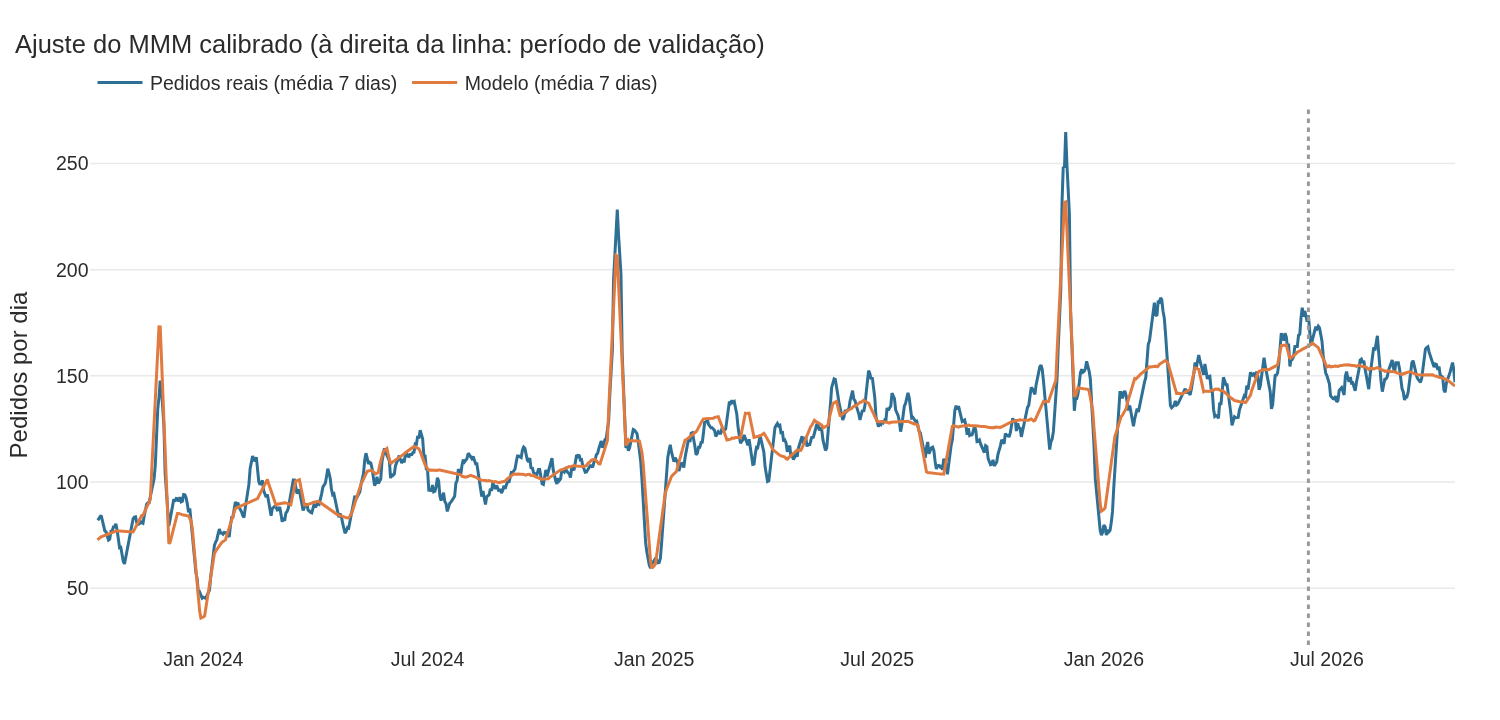

In [6]:
contrib_livre, contrib = contribuicoes(res_livre, False), contribuicoes(res_cal, True)
b, M, Z = ajustar(H, len(y))
df["ajuste"] = Z @ b
r2 = 1 - ((y - df.ajuste) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"R² na série inteira: {r2:.3f}")

fig = go.Figure()
fig.add_scatter(x=df.index, y=df.pedidos.rolling(7).mean(), name="Pedidos reais (média 7 dias)", line=dict(color=COR_REAL))
fig.add_scatter(x=df.index, y=df.ajuste.rolling(7).mean(), name="Modelo (média 7 dias)", line=dict(color=COR_PREVISTO))
fig.add_vline(x=df.index[corte], line_dash="dot", line_color="#999")
fig.update_layout(title="Ajuste do MMM calibrado (à direita da linha: período de validação)", yaxis_title="Pedidos por dia")
fig.show()

## 3. Comparison: platform × MMM × pause test × truth

In [7]:
dem = verdade("demanda_diaria.csv").assign(data=lambda d: pd.to_datetime(d.data)).set_index("data").loc[df.index]
inv_total = df[CANAIS].sum()
reportado = inv.groupby("canal").valor_reportado.sum().reindex(CANAIS)

tab = pd.DataFrame({
    "Investimento": inv_total,
    "ROAS reportado pela plataforma": reportado / inv_total,
    "iROAS MMM sem calibração": contrib_livre.median(axis=1) * ticket / inv_total,
    "iROAS MMM calibrado": contrib.median(axis=1) * ticket / inv_total,
    "faixa (10 melhores ajustes)": [f"{lo:.2f} a {hi:.2f}" for lo, hi in zip(contrib.min(axis=1) * ticket / inv_total, contrib.max(axis=1) * ticket / inv_total)],
    "iROAS verdadeiro": pd.Series({c: dem[f"inc_{c}"].sum() for c in CANAIS}) * ticket / inv_total,
})
tab.loc["meta_prospeccao", "iROAS teste de pausa"] = ped_por_mil_pausa * ticket / 1000
tab.rename(index=ROTULO).style.format({"Investimento": brl, "ROAS reportado pela plataforma": "{:.2f}", "iROAS MMM sem calibração": "{:.2f}", "iROAS MMM calibrado": "{:.2f}",
                                       "iROAS verdadeiro": "{:.2f}", "iROAS teste de pausa": "{:.2f}"}, na_rep="—")

,Investimento,ROAS reportado pela plataforma,iROAS MMM sem calibração,iROAS MMM calibrado,faixa (10 melhores ajustes),iROAS verdadeiro,iROAS teste de pausa
Meta prospecção,R$ 1.969.950,4.04,2.14,4.09,3.91 a 4.17,2.59,2.95
Meta remarketing,R$ 533.554,6.20,18.55,1.99,1.54 a 2.57,0.86,—
Google marca,R$ 138.875,33.38,89.19,1.35,1.22 a 1.47,0.65,—
Google search (genérico),R$ 653.031,3.49,0.85,1.92,1.27 a 2.47,2.15,—
Google Shopping/PMax,R$ 937.242,5.37,0.00,1.80,1.29 a 2.19,2.05,—
Google Demand Gen,R$ 62.875,1.19,0.00,1.39,1.32 a 1.41,0.38,—


The **uncalibrated** MMM gives absurd returns for remarketing and brand search: those channels' spend follows demand (more visitors create a larger remarketing audience and more brand searches), and the model mistakes that correlation for an effect. That is why the chart below only shows the calibrated version.

The "true iROAS" comes from the incremental orders the generator attributed to each channel (`data/verdade/demanda_diaria.csv`), converted to revenue with the real average order value, the same conversion used in the MMM.

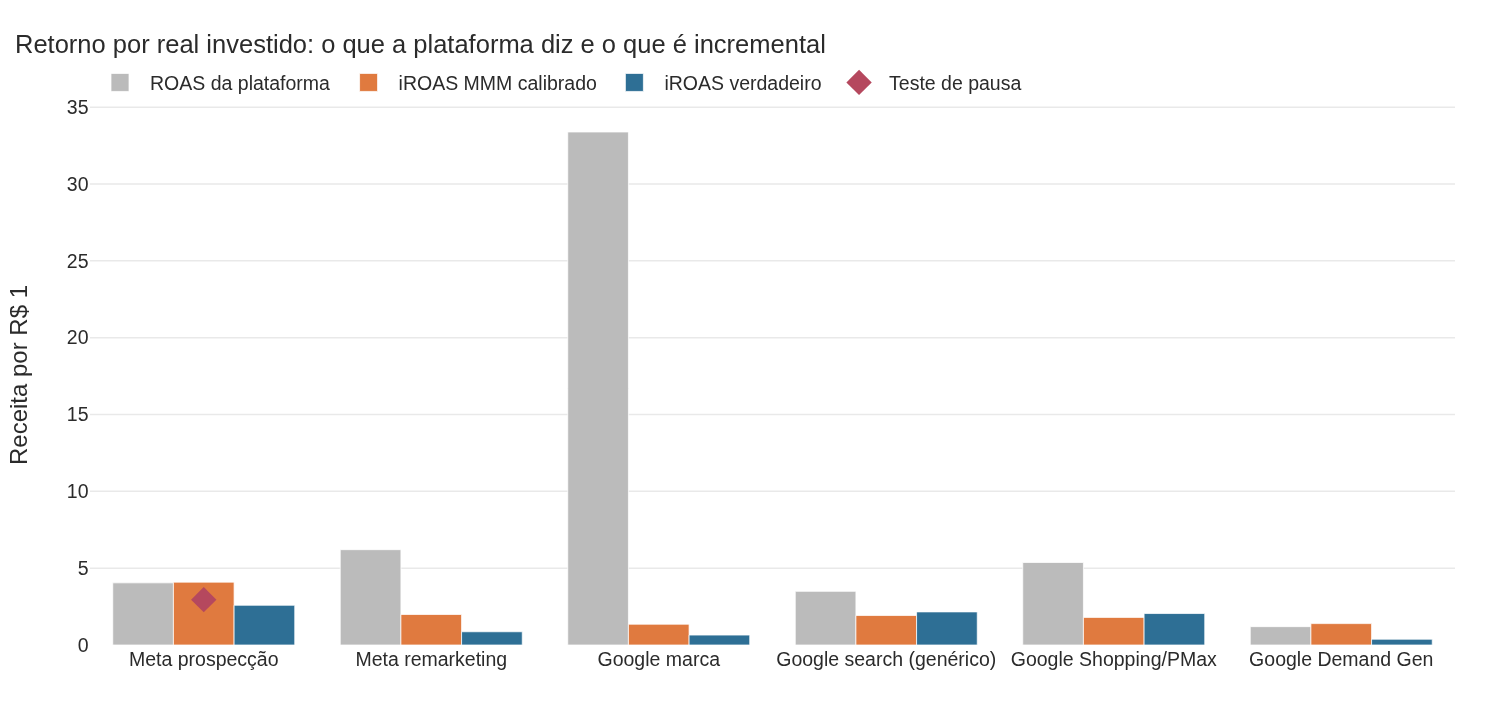

In [8]:
t = tab.rename(index=ROTULO)
fig = go.Figure()
fig.add_bar(x=t.index, y=t["ROAS reportado pela plataforma"], name="ROAS da plataforma", marker_color="#bbbbbb")
fig.add_bar(x=t.index, y=t["iROAS MMM calibrado"], name="iROAS MMM calibrado", marker_color=COR_PREVISTO)
fig.add_bar(x=t.index, y=t["iROAS verdadeiro"], name="iROAS verdadeiro", marker_color=COR_REAL)
fig.add_scatter(x=t.index, y=t["iROAS teste de pausa"], name="Teste de pausa", mode="markers",
                marker=dict(symbol="diamond", size=13, color=COR_DESTAQUE))
fig.update_layout(barmode="group", title="Retorno por real investido: o que a plataforma diz e o que é incremental", yaxis_title="Receita por R$ 1")
fig.show()

## Business conclusions

1. **Platform ROAS is not fit for budget decisions.** Meta remarketing reports a ROAS of 6.2 and brand search 33.4, but the true incremental return is 0.86 and 0.65: most of those sales would happen without the ad. These two channels consume R$ 670k (16% of the budget) and return less than they cost.
2. **The pause test got it right.** Three weeks without Meta prospecting cost ~327 orders (±125), an iROAS of 2.95 against 2.59 in the truth, within the confidence interval. With R$ 32k saved, it is the most reliable measure in the base.
3. **The MMM alone misleads.** Without calibration, it gives an iROAS of 18.6 for remarketing and 89 for brand, because those channels' spend rises with demand. With the pause test as a prior, the estimates become plausible: Google search (1.9) and Shopping/PMax (1.8) land close to the truth (2.2 and 2.1). Remarketing, brand and Demand Gen remain overestimated (1.4 to 2.0, against 0.4 to 0.9 in the truth), and Meta prospecting goes up to 4.1.
4. **Recommendation:** move budget from remarketing and brand search to Meta prospecting and Google search/Shopping. Before cutting, run pause (or geo) tests on those two channels, which are exactly where the MMM is least reliable. Each new test becomes a prior and improves the model.